### Retrieving the core flow from geomagnetic measures using _physics-informed neural networks_ (PiNNs)

In [1]:
%pip install pygeodyntools --upgrade

Note: you may need to restart the kernel to use updated packages.


In [2]:
import torch
import numpy
import scipy
import pygeotools
import matplotlib.pyplot as plt
import tqdm
import time
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean
import math
import torch.nn.functional as F

In [3]:
# Setting the seed
torch.manual_seed(0)
torch.use_deterministic_algorithms(True)

### 0) Useful parameters

In [4]:
time_of_study: int = 2020       # Time of the study

number_of_inputs: int = 2       # Number of input variables (θ and φ angles)
number_of_outputs: int = 3      # Number of output variables (uθ, uφ, br)

number_of_layers: int = 1       # Number of layers
number_of_neurons: int = 16     # Number of neurons

number_epochs: int = 10000      # Number of epochs

fine_tune: bool = True          # Fine-tuning the model using L-BFGS?
number_steps: int = 500         # Number of steps for the fine tuning

grid_size: int = 3              # Using 3deg per 3deg grid

patch: tuple = (5, 85, 5, 85)   # Defining the patch

use_synthetic_sv: bool = True   # Do we use a synthetic SV?

estimate_small_scale_br: bool = False # Do we estimate the small-scales of Br?

filter_br: bool = False          # Do we filter Br?
σ_filter_br: float = 0.1

λ_dbrdt = 1
λ_br = 1
λ_tg = 1e4
λ_tor = 0
λ_wn = 1e-4
λ_sn = 0
λ_f_br = 0

losses: dict = {                # The different losses to use (available: misfit_dbrdt, misfit_br, tangential_geostrophy, weak_norm, strong_norm, vorticity)
    "misfit_dbrdt": λ_dbrdt,
    "misfit_br": λ_br,
    "tangential_geostrophy": λ_tg,
    "weak_norm": λ_wn,

    "spectral_u": 1.0 # Testing
    # "frozen_br": λ_f_br
}

### 1) Retrieving the data from geodynamo simulations

In [5]:
# Initializing the library
pygeo = pygeotools.pygeotools()

# Defining the path and the name of the model
model_path = "geodynamo.hdf5"
model_name = "model_geodynamo"

# Loading the model
pygeo.loadModel(model_name, "pygeodyn_hdf5", model_path)

# Defining the grid for computing the fields
# It is 3°x3° angular grid
if not pygeo.isGrid(f"{grid_size}deg"):
    pygeo.addGrid(f"{grid_size}deg", grid_size, grid_size)

# Setting the grid
pygeo.setGrid(f"{grid_size}deg")

# Retrieving the angles
_, (thetas, phis) = pygeo.getCurrentGrid()

# Defining the context for computing the SV and MF, and U
context_sv = {"lmax": 13, "r": pygeo.constants["rCore"]}
context_mf = {"lmax": 18, "r": pygeo.constants["rCore"]}
context_u = {"lmax": 18, "r": pygeo.constants["rCore"]}

# Computing the fields
SV = pygeo.addMeasure(model_name, "SV", context_sv)
MF = pygeo.addMeasure(model_name, "MF", context_mf)
U = pygeo.addMeasure(model_name, "U", context_u)

# Retrieving the times
times = pygeo.getQuantity(model_name, "times")

# Retrieving the associated times index
idx_times = numpy.argmin(numpy.abs(times - time_of_study))

# Retrieving the components of the fields
dbrdt_obs = SV[idx_times, ..., 0]
br_obs = MF[idx_times, ..., 0]
dbrdth_obs = numpy.gradient(br_obs, thetas, axis=0)
dbrdph_obs = numpy.gradient(br_obs, phis, axis=1)
uθ_obs = U[idx_times, ..., 1]
uφ_obs = U[idx_times, ..., 2]

# Storing into the observations dict
observations = {
    "dbrdt": dbrdt_obs, "br": br_obs, "uth": uθ_obs, "uph": uφ_obs, "dbrdth": dbrdth_obs, "dbrdph": dbrdph_obs
}

pygeotools was initialized with `verbose=True`.
18


### 1 bis) Generating synthetic SV

In [6]:
r = 3480.

In [7]:
if use_synthetic_sv:

    # Creating synthetic data
    θ = thetas
    φ = phis

    θ_grid, φ_grid = numpy.meshgrid(θ, φ, indexing="ij")

    sinθ = numpy.sin(θ_grid).clip(1e-1, 1)
    cosθ = numpy.cos(θ_grid)

    dθ = numpy.gradient(θ).mean()
    dφ = numpy.gradient(φ).mean()

    dΩ = sinθ * dθ * dφ

    duθdθ = numpy.gradient(uθ_obs, θ, axis=0)
    duθdφ = numpy.gradient(uθ_obs, φ, axis=1)
    duφdθ = numpy.gradient(uφ_obs, θ, axis=0)
    duφdφ = numpy.gradient(uφ_obs, φ, axis=1)

    divh_uh= (1 / (r * sinθ)) * (duθdθ * sinθ + uθ_obs * cosθ + duφdφ)

    dbrdth = numpy.gradient(br_obs, θ, axis=0)
    dbrdph = numpy.gradient(br_obs, φ, axis=1)

    observations["dbrdth"] = dbrdth
    observations["dbrdph"] = dbrdph

    gradθbr = dbrdth / r
    gradφbr = dbrdph / (r * sinθ)

    br_divh_uh = br_obs * divh_uh
    uh_dot_gradbr = uθ_obs * gradθbr + uφ_obs * gradφbr

    dbrdt = -(br_divh_uh + uh_dot_gradbr)

    # Overwriting the dbrdt observation
    observations["dbrdt"] = dbrdt

### 2) Defining the network architecture

In [8]:
class Network(torch.nn.Module):

    def __init__(self, nb_input: int, nb_output: int, nb_layer: int, nb_neuron: int) -> None:
        
        # Initializing the torch module
        super(Network, self).__init__()

        # Initializing the layers
        layers = []

        # Creating the first layer
        layers.append(torch.nn.Linear(nb_input, nb_neuron))
        layers.append(torch.nn.Tanh())

        # Creating the hidden layers
        for _ in range(nb_layer):
            layers.append(torch.nn.Linear(nb_neuron, nb_neuron))
            layers.append(torch.nn.Tanh())

        # Creating the last layer
        layers.append(torch.nn.Linear(nb_neuron, nb_output))

        # Creating the network
        self.net: torch.nn.Sequential = torch.nn.Sequential(*layers)

    def forward(self, inputs: torch.Tensor) -> torch.Tensor:
        return self.net(inputs)

In [9]:
# Defining the network instance
network_instance = Network(number_of_inputs, number_of_outputs, number_of_layers, number_of_neurons)

### 3) Creating the tensors

In [10]:
# Function to create a tensor from a numpy array
def as_tensor(numpy_array: numpy.ndarray, requires_grad: bool = False) -> torch.Tensor:
    return torch.tensor(numpy_array, dtype=torch.float32, requires_grad=requires_grad)

# Function to create an autograd tensor from a tensor
def as_grad(tensor: torch.Tensor, input: torch.Tensor) -> torch.Tensor:
    return torch.autograd.grad(tensor, input, torch.ones_like(tensor), retain_graph=True, create_graph=True)[0]

In [11]:
# Converting back the angles in degrees
thetas_deg: numpy.ndarray = numpy.round(numpy.rad2deg(thetas), 3)
phis_deg: numpy.ndarray = numpy.round(numpy.rad2deg(phis), 3)

# Retrieving the corresponding indexes for the patch
idx_theta_min = numpy.argmin(numpy.abs(thetas_deg - patch[0]))
idx_theta_max = numpy.argmin(numpy.abs(thetas_deg - patch[1]))
idx_phi_min = numpy.argmin(numpy.abs(phis_deg - patch[2]))
idx_phi_max = numpy.argmin(numpy.abs(phis_deg - patch[3]))

# Avoiding conflict with the slice end
idx_theta_max = None if idx_theta_max + 1 == len(thetas_deg) else idx_theta_max + 1
idx_phi_max = None if idx_phi_max + 1 == len(phis_deg) else idx_phi_max + 1

# Defining the slices (to ease the notation afterwards)
slice_thetas = slice(idx_theta_min, idx_theta_max, 1)
slice_phis = slice(idx_phi_min, idx_phi_max, 1)

# Creating the grid
thetas_grid, phis_grid = numpy.meshgrid(thetas, phis, indexing="ij")

# Defining the tensors from the observations
tensors = {}

# Looping over all observations
for name in observations:
    field = observations[name][slice_thetas, slice_phis].reshape(-1, 1)
    tensors[name] = torch.tensor(field, dtype=torch.float32)

# Defining the angular grid tensor
thetas_tensor = as_tensor(thetas_grid[slice_thetas, slice_phis].reshape(-1, 1), requires_grad=True)
phis_tensor = as_tensor(phis_grid[slice_thetas, slice_phis].reshape(-1, 1), requires_grad=True)

# Updating the list of tensors
tensors.update({
    "thetas": thetas_tensor, "phis": phis_tensor
})

# Defining the input tensor
input_tensor = torch.concatenate([thetas_tensor, phis_tensor], dim=1)

In [12]:
field_shape = phis_grid[slice_thetas, slice_phis].shape

### 4) Defining the loss function

In [13]:
# Filter method
def gaussian_filter_2d_torch(input, sigma, truncate=100):
    """
    Applying a 2-d Gaussian filter on a map
        - (tensor) `input` the input tensor
        - (int) `sigma` the standard deviation for the Gaussian kernel
        - (int) `truncate` truncate the filter at this many standard deviation
    """

    if len(input.shape) == 2 and input.shape[-1] == 1:
        input = input.reshape(observations["br"][slice_thetas, slice_phis].shape)

    # Computing the kernel size
    kernel_size = 2 * math.ceil(sigma * truncate) + 1

    # Creating the 1-d kernel
    x = torch.arange(kernel_size).float()  - (kernel_size - 1) / 2
    kernel_1d = torch.exp(-(x / sigma)**2 / 2)
    kernel_1d /= kernel_1d.sum()

    # Creating the 2-d kernel
    kernel_2d =  torch.outer(kernel_1d, kernel_1d)

    # Formatting the kernel for the conv2d layer (H, W) -> (B = 1, C = 1, H, W)
    kernel_2d = kernel_2d.unsqueeze(0).unsqueeze(0)

    # Applying the 2-d convolution
    output = F.conv2d(input.unsqueeze(0).unsqueeze(0), kernel_2d, padding="same")

    # Removing the batch (B) and channel (C) dimensions
    return output.squeeze(0).squeeze(0).reshape(-1, 1)

In [14]:
# Computing the spherical harmonics
def spherical_harmonics(lmax, thetas, phis):
    # Defining the degrees and modes
    l = numpy.arange(0, lmax + 1, 1)
    m = l[::]

    # Creating the meshing
    θ, φ = numpy.meshgrid(thetas, phis, indexing="ij")
    L, M = numpy.meshgrid(l, m, indexing="ij")

    # Computing the unormalized associated Legendre polynomials
    # (restricting to m >= 0)
    z = numpy.cos(θ)
    p, *_ = scipy.special.assoc_legendre_p_all(lmax, lmax, z, branch_cut=2, diff_n=0)
    p = p[:, :(lmax + 1), ...]

    def dirac(x):
        return numpy.float64(x == 0)
    
    def fact(x):
        return numpy.float64(scipy.special.factorial(x, exact=False, extend="zero"))

    # Computing Schmidt quasi-normalisation
    schmidt_norm = numpy.sqrt((2 - dirac(M)) * fact(L - M) / fact(L + M))

    # Adding the norm
    p = numpy.einsum('ij,ijkl->ijkl', schmidt_norm, p, optimize=True)

    # Defining cos(mφ) and sin(mφ)
    mφ = numpy.einsum('ij,kl->ijkl', M, φ, optimize=True)
    cos_mφ = numpy.cos(mφ)
    sin_mφ = numpy.sin(mφ)

    # Defining the real spherical harmonics
    y_cos = cos_mφ * p
    y_sin = sin_mφ * p

    return y_cos, y_sin

In [15]:

try:
    import opt_einsum as oe
    _USE_OE = True
except Exception:
    _USE_OE = False

# 1) Ensure a spectral Br weight is present
#    If you already created these elsewhere, keep your values and skip this.
lmax_spec = locals().get("lmax_spec", 13)     # keep your default if already set
λ_spec_br  = locals().get("λ_spec_br", 1e-2)  # keep your default if already set
if "spectral_br" not in losses:
    losses["spectral_br"] = λ_spec_br

# 2) Build spectral basis for Br at the truncation we'll use in the spectrum
l_trunc_spec = lmax_spec
y_cos_spec, y_sin_spec = spherical_harmonics(l_trunc_spec, thetas, phis)

# Full-sphere integration weights
θ_full, φ_full = numpy.meshgrid(thetas, phis, indexing="ij")
sinθ_full = numpy.sin(θ_full)
dθ_full   = numpy.gradient(thetas).mean()
dφ_full   = numpy.gradient(phis).mean()
dΩ_full   = sinθ_full * dθ_full * dφ_full

# Schmidt normalization factor C_{l} = (2l+1)/(4π) replicated over (l,m)
L_spec, M_spec = numpy.meshgrid(numpy.arange(l_trunc_spec+1), numpy.arange(l_trunc_spec+1))
C_spec = (2*L_spec + 1) / (4*numpy.pi)

# 3) Compute S_obs_mean by projecting Br from MF at all times
#    MF is already loaded above in your code; Br_all = MF[...,0]  shape: (Nt, Nθ, Nφ)
Br_all = MF[..., 0]   # (Nt, Nθ, Nφ)

S_sum = None
for it in range(Br_all.shape[0]):
    Br_t = Br_all[it]  # (Nθ, Nφ)

    if _USE_OE:
        coeffs_cos_t = oe.contract('ijkl,ij,kl,kl->ij', y_cos_spec, C_spec, Br_t, dΩ_full, optimize='optimal')
        coeffs_sin_t = oe.contract('ijkl,ij,kl,kl->ij', y_sin_spec, C_spec, Br_t, dΩ_full, optimize='optimal')
    else:
        coeffs_cos_t = numpy.einsum('ijkl,ij,kl,kl->ij', y_cos_spec, C_spec, Br_t, dΩ_full, optimize=True)
        coeffs_sin_t = numpy.einsum('ijkl,ij,kl,kl->ij', y_sin_spec, C_spec, Br_t, dΩ_full, optimize=True)

    # degree spectrum S_l = sum_{m=0..l}(a_lm^2 + b_lm^2)/(2l+1)
    # (coeffs_cos_t, coeffs_sin_t) have shape (l+1, l+1)
    S_t = numpy.sum(coeffs_cos_t**2 + coeffs_sin_t**2, axis=1) / (2*numpy.arange(l_trunc_spec+1) + 1)

    S_sum = S_t if S_sum is None else (S_sum + S_t)

S_obs_mean = S_sum / Br_all.shape[0]  # average over time

# 4) Convert all things needed in the loss to torch tensors (once!)
y_cos_spec_t = torch.tensor(y_cos_spec, dtype=torch.float32)
y_sin_spec_t = torch.tensor(y_sin_spec, dtype=torch.float32)
C_spec_t     = torch.tensor(C_spec,     dtype=torch.float32)
dΩ_full_t    = torch.tensor(dΩ_full,    dtype=torch.float32)
S_obs_mean_t = torch.tensor(S_obs_mean, dtype=torch.float32)
# ======== End Block A ========


In [16]:
# Pre-computing the basis functions
y_cos, y_sin = spherical_harmonics(18, thetas, phis)

# Converting into tensors
y_cos_tensor = as_tensor(y_cos[..., slice_thetas, slice_phis])
y_sin_tensor = as_tensor(y_sin[..., slice_thetas, slice_phis])

In [17]:
# Method for computing the Gauss coefficients
def spectral_transform(field: torch.Tensor, l_trunc: int = 18) -> tuple:
    l = torch.arange(0, l_trunc + 1, 1)

    # Surely redundant... but faster
    thetas_tensor = as_tensor(thetas)
    phis_tensor = as_tensor(phis)

    # Meshing the angles and degrees
    θ, φ = torch.meshgrid(thetas_tensor, phis_tensor, indexing="ij")
    L, M = torch.meshgrid(l, l, indexing="ij")

    # Defining the surface element
    dθ = numpy.gradient(thetas).mean()
    dφ = numpy.gradient(phis).mean()
    sinθ = torch.sin(θ[slice_thetas, slice_phis])
    dΩ = sinθ * dθ * dφ

    # Defining the normalisation constant for the Gauss coefficient
    C = (2 * L + 1) / (4 * numpy.pi)

    # Decomposing the field
    coeffs_cos = torch.einsum('ijkl,ij,kl->ij', y_cos_tensor, C, field * dΩ)
    coeffs_sin = torch.einsum('ijkl,ij,kl->ij', y_sin_tensor, C, field * dΩ)

    return coeffs_cos, coeffs_sin

In [18]:

l_trunc = lmax_spec  # keep consistent with your spectral truncation

# Build real Schmidt quasi-normalized spherical harmonics on the FULL sphere
y_cos_full, y_sin_full = spherical_harmonics(l_trunc, thetas, phis)

# Normalization factor C_l = (2l+1)/(4π), broadcasted to (l,m)
L_full, M_full = numpy.meshgrid(numpy.arange(l_trunc+1), numpy.arange(l_trunc+1))
C_full = (2*L_full + 1) / (4*numpy.pi)

# U already loaded above: U = pygeo.addMeasure(model_name, "U", context_u)  # shape (Nt, Nθ, Nφ, 3)
U_all = U[..., 1:3]  # keep only (uθ, uφ), shape (Nt, Nθ, Nφ, 2)

def degree_spectrum_from_components(uθ_map, uφ_map):
    """
    S_u(l) = (1/(2l+1)) * sum_m [ |aθ_lm|^2 + |bθ_lm|^2 + |aφ_lm|^2 + |bφ_lm|^2 ]
    where coefficients are projections onto real SH with Schmidt norm and C_l factor.
    """
    coeffsθ_cos = numpy.einsum('ijkl,ij,kl,kl->ij', y_cos_full, C_full, uθ_map, dΩ_full, optimize=True)
    coeffsθ_sin = numpy.einsum('ijkl,ij,kl,kl->ij', y_sin_full, C_full, uθ_map, dΩ_full, optimize=True)
    coeffsφ_cos = numpy.einsum('ijkl,ij,kl,kl->ij', y_cos_full, C_full, uφ_map, dΩ_full, optimize=True)
    coeffsφ_sin = numpy.einsum('ijkl,ij,kl,kl->ij', y_sin_full, C_full, uφ_map, dΩ_full, optimize=True)

    S_u = numpy.zeros(l_trunc+1, dtype=numpy.float64)
    for l in range(l_trunc+1):
        S_u[l] = (
            numpy.sum(coeffsθ_cos[l, :l+1]**2 + coeffsθ_sin[l, :l+1]**2) +
            numpy.sum(coeffsφ_cos[l, :l+1]**2 + coeffsφ_sin[l, :l+1]**2)
        ) / (2*l + 1)
    return S_u

# Time-averaged observed KE spectrum
Nt = U_all.shape[0]
S_u_sum = None
for it in range(Nt):
    uθ_t = U_all[it, ..., 0]
    uφ_t = U_all[it, ..., 1]
    S_u_t = degree_spectrum_from_components(uθ_t, uφ_t)
    S_u_sum = S_u_t if S_u_sum is None else (S_u_sum + S_u_t)

S_u_obs_mean = torch.tensor(S_u_sum / Nt, dtype=torch.float32)  # <- target for spectral_u loss




# 1) Full-sphere angle grid (with autograd), and concatenated input
Θ_full_np, Φ_full_np = numpy.meshgrid(thetas, phis, indexing="ij")
thetas_full_t = torch.tensor(Θ_full_np.reshape(-1, 1), dtype=torch.float32, requires_grad=True)
phis_full_t   = torch.tensor(Φ_full_np.reshape(-1, 1), dtype=torch.float32, requires_grad=True)
inp_full      = torch.cat([thetas_full_t, phis_full_t], dim=1)

# 2) Torch versions of SH bases and integration weights (flow spectrum)
ycos_t = torch.tensor(y_cos_full, dtype=torch.float32)
ysin_t = torch.tensor(y_sin_full, dtype=torch.float32)
C_t    = torch.tensor(C_full,     dtype=torch.float32)
dΩ_t   = torch.tensor(dΩ_full,    dtype=torch.float32)


# 3) Torch versions for Br spectrum
y_cos_spec_t = torch.tensor(y_cos_spec, dtype=torch.float32)
y_sin_spec_t = torch.tensor(y_sin_spec, dtype=torch.float32)
C_spec_t     = torch.tensor(C_spec,     dtype=torch.float32)
dΩ_full_t    = torch.tensor(dΩ_full,    dtype=torch.float32)
S_obs_mean_t = torch.tensor(S_obs_mean, dtype=torch.float32)
degrees_br   = torch.arange(l_trunc_spec + 1, dtype=torch.float32)

In [19]:
# Function for computing the loss function
def compute_loss(input: torch.Tensor, return_fields: bool = False) -> tuple | torch.Tensor:

    # Defining the outer core radius
    r = torch.tensor(pygeo.constants["rCore"], dtype=torch.float32)
    
    # Retrieving the predictions from the network
    predictions = network_instance(input)


    preds_full = None
    if (("spectral_br" in losses and losses["spectral_br"] > 0) or
        ("spectral_u"  in losses and losses["spectral_u"]  > 0)):
        preds_full = network_instance(inp_full)

    # Separating between the flow components and br
    # Here, the flow components are toroidal and poloidal scalar fields, t and s
    t: torch.Tensor = predictions[...,0:1]
    s: torch.Tensor = predictions[...,1:2]
    br: torch.Tensor = predictions[...,2:3]

    # Retrieving the observations
    dbrdt_obs: torch.Tensor = tensors["dbrdt"]
    br_obs: torch.Tensor = tensors["br"]

    # Computing the derivatives of the observed Br (in we are estimating the small-scales)
    if estimate_small_scale_br:
        dbrdθ_obs = tensors["dbrdth"]
        dbrdφ_obs = tensors["dbrdph"]

    # Retrieving angles (ensuring gradient calculations)
    θ: torch.Tensor = tensors["thetas"]
    φ: torch.Tensor = tensors["phis"]

    # Defining useful quantities
    sinθ: torch.Tensor = torch.sin(θ).clamp(1e-1, 1)
    cosθ: torch.Tensor = torch.cos(θ)

    # Defining the derivatives of t and s
    dtdθ: torch.Tensor = as_grad(t, θ)
    dtdφ: torch.Tensor = as_grad(t, φ)
    dsdθ: torch.Tensor = as_grad(s, θ)
    dsdφ: torch.Tensor = as_grad(s, φ)

    # Retrieving uθ and uφ
    uθ: torch.Tensor = (1 / sinθ) * dtdφ + dsdθ
    uφ: torch.Tensor = -dtdθ + (1 / sinθ) * dsdφ

    # 1) Computing the SV

    # Defining the equation of induction
    # We have: dbr / dt = -divh(uh br) = -br divh(uh) - uh ⋅  gradh(br)

    # Computing the derivatives of uθ and uφ
    duθdθ: torch.Tensor = as_grad(uθ, θ)
    duθdφ: torch.Tensor = as_grad(uθ, φ)
    duφdθ: torch.Tensor = as_grad(uφ, θ)
    duφdφ: torch.Tensor = as_grad(uφ, φ)

    # Computing the derivatives of br
    dbrdθ: torch.Tensor = as_grad(br, θ)
    dbrdφ: torch.Tensor = as_grad(br, φ)

    # Computing divh(uh)
    divh_uh: torch.Tensor = (1 / (r * sinθ)) * (duθdθ * sinθ + uθ * cosθ + duφdφ)

    # Computing gradh(br)
    if estimate_small_scale_br:
        gradθ_br: torch.Tensor = (1 / r) * (dbrdθ + dbrdθ_obs)
        gradφ_br: torch.Tensor = (1 / (r * sinθ)) * (dbrdφ + dbrdφ_obs)

        dbrdt = -((br + br_obs) * divh_uh + gradθ_br * uθ + gradφ_br * uφ)
    else:
        gradθ_br: torch.Tensor = (1 / r) * dbrdθ
        gradφ_br: torch.Tensor = (1 / (r * sinθ)) * dbrdφ

        dbrdt = -(br * divh_uh + gradθ_br * uθ + gradφ_br * uφ)

    # 2) Computing the loss functions

    # Defining the total loss function
    total_loss: torch.Tensor = torch.tensor(0, dtype=torch.float32)

    if "misfit_dbrdt" in losses:
        misfit_dbrdt: torch.Tensor = (dbrdt - dbrdt_obs).pow(2).mean() / dbrdt_obs.pow(2).mean()
        loss = losses["misfit_dbrdt"] * misfit_dbrdt
        total_loss += loss

        saved_losses["misfit_dbrdt"].append(loss.clone().detach().numpy())

    if "misfit_br" in losses:
        if filter_br:
            br_pred = gaussian_filter_2d_torch(br, sigma=σ_filter_br)
            br_obs_filter = gaussian_filter_2d_torch(br_obs, sigma=σ_filter_br)
        else:
            br_pred = br
            br_obs_filter = br_obs

        misfit_br: torch.Tensor = (br_pred - br_obs_filter).pow(2).mean() / br_obs_filter.pow(2).mean()
        loss = losses["misfit_br"] * misfit_br
        total_loss += loss

        saved_losses["misfit_br"].append(loss.clone().detach().numpy())

    if "tangential_geostrophy" in losses:
        tangential_geostrophy: torch.Tensor = (cosθ * divh_uh - sinθ * uθ / r).pow(2).mean()
        loss = losses["tangential_geostrophy"] * tangential_geostrophy
        total_loss += loss

        saved_losses["tangential_geostrophy"].append(loss.clone().detach().numpy())

    if "toroidal" in losses:
        toroidal: torch.Tensor = divh_uh.pow(2).mean()
        loss = losses["toroidal"] * toroidal
        total_loss += loss

        saved_losses["toroidal"].append(loss.clone().detach().numpy())

    if "weak_norm" in losses:
        dθ = numpy.gradient(thetas).mean()
        dφ = numpy.gradient(phis).mean()
        dΩ = sinθ * dθ * dφ

        weak_norm: torch.Tensor = torch.sum((uθ**2 + uφ**2) * dΩ) / torch.sum(dΩ)

        loss = losses["weak_norm"] * weak_norm
        total_loss += loss

        saved_losses["weak_norm"].append(loss.clone().detach().numpy())

    if "strong_norm" in losses:
        dθ = numpy.gradient(thetas).mean()
        dφ = numpy.gradient(phis).mean()
        dΩ = sinθ * dθ * dφ

        d2uθdθ: torch.Tensor = as_grad(duθdθ, θ)
        d2uθdφ: torch.Tensor = as_grad(duθdφ, φ)
        d2uφdθ: torch.Tensor = as_grad(duφdθ, θ)
        d2uφdφ: torch.Tensor = as_grad(duφdφ, φ)

        Δuθ = (1 / (r**2 * sinθ)) * (cosθ * duθdθ + sinθ * d2uθdθ) + (1 / (r * sinθ)**2) * d2uθdφ
        Δuφ = (1 / (r**2 * sinθ)) * (cosθ * duφdθ + sinθ * d2uφdθ) + (1 / (r * sinθ)**2) * d2uφdφ

        strong_norm: torch.Tensor = torch.sum((Δuθ**2 + Δuφ**2) * dΩ) / torch.sum(dΩ)

        loss = losses["strong_norm"] * strong_norm
        total_loss += loss

        saved_losses["strong_norm"].append(loss.clone().detach().numpy())

    if "frozen_br" in losses:
        dθ = numpy.gradient(thetas).mean()
        dφ = numpy.gradient(phis).mean()
        dΩ = sinθ * dθ * dφ

        frozen_br: torch.Tensor = torch.sum(torch.abs(br) * dΩ) / torch.sum(dΩ)

        loss = losses["frozen_br"] * frozen_br
        total_loss += loss

        saved_losses["frozen_br"].append(loss.clone().detach().numpy())

    # -------------------- REUSED CACHE: Spectral Br --------------------
    if "spectral_br" in losses and losses["spectral_br"] > 0:

        br_full    = preds_full[..., 2:3].reshape(len(thetas), len(phis))   # (Nθ, Nφ)

        coeffs_cos_pred = torch.einsum('ijkl,ij,kl,kl->ij',
                                       y_cos_spec_t, C_spec_t, br_full, dΩ_full_t)
        coeffs_sin_pred = torch.einsum('ijkl,ij,kl,kl->ij',
                                       y_sin_spec_t, C_spec_t, br_full, dΩ_full_t)

        S_pred  = torch.sum(coeffs_cos_pred**2 + coeffs_sin_pred**2, dim=1) / (2*degrees_br + 1)

        num   = (S_obs_mean_t[1:] - S_pred[1:])  # skip l=0
        spec_misfit = torch.mean((num / (S_obs_mean_t[1:] + 1e-12))**2)

        loss = losses["spectral_br"] * spec_misfit
        total_loss += loss
        saved_losses.setdefault("spectral_br", []).append(loss.detach().cpu().numpy())

    # -------------------- REUSED CACHE: Spectral flow --------------------
    if "spectral_u" in losses and losses["spectral_u"] > 0:

        t_full = preds_full[..., 0:1]
        s_full = preds_full[..., 1:2]

        # Gradients on full sphere (cached angle tensors)
        dtdθ_full = torch.autograd.grad(t_full, thetas_full_t, torch.ones_like(t_full), retain_graph=True, create_graph=True)[0]
        dtdφ_full = torch.autograd.grad(t_full, phis_full_t,   torch.ones_like(t_full), retain_graph=True, create_graph=True)[0]
        dsdθ_full = torch.autograd.grad(s_full, thetas_full_t, torch.ones_like(s_full), retain_graph=True, create_graph=True)[0]
        dsdφ_full = torch.autograd.grad(s_full, phis_full_t,   torch.ones_like(s_full), retain_graph=True, create_graph=True)[0]

        sinθ_f = torch.sin(thetas_full_t).clamp(1e-2, 1)

        # Flow components on full sphere
        uθ_full = ((1.0 / sinθ_f) * dtdφ_full + dsdθ_full).reshape(len(thetas), len(phis))
        uφ_full = (-dtdθ_full + (1.0 / sinθ_f) * dsdφ_full).reshape(len(thetas), len(phis))

        # Project onto cached SH basis/weights
        coeffsθ_cos = torch.einsum('ijkl,ij,kl,kl->ij', ycos_t, C_t, uθ_full, dΩ_t)
        coeffsθ_sin = torch.einsum('ijkl,ij,kl,kl->ij', ysin_t, C_t, uθ_full, dΩ_t)
        coeffsφ_cos = torch.einsum('ijkl,ij,kl,kl->ij', ycos_t, C_t, uφ_full, dΩ_t)
        coeffsφ_sin = torch.einsum('ijkl,ij,kl,kl->ij', ysin_t, C_t, uφ_full, dΩ_t)

        # Degree KE spectrum of predicted flow
        S_u_pred = []
        for l in range(l_trunc+1):
            S_l = (
                torch.sum(coeffsθ_cos[l, :l+1]**2 + coeffsθ_sin[l, :l+1]**2) +
                torch.sum(coeffsφ_cos[l, :l+1]**2 + coeffsφ_sin[l, :l+1]**2)
            ) / (2*l + 1)
            S_u_pred.append(S_l)
        S_u_pred = torch.stack(S_u_pred, dim=0)

        # Normalized misfit, skip l=0
        eps = 1e-12
        spec_misfit_u = torch.mean(((S_u_obs_mean[1:] - S_u_pred[1:]) / (S_u_obs_mean[1:] + eps))**2)

        loss = losses["spectral_u"] * spec_misfit_u
        total_loss += loss
        saved_losses.setdefault("spectral_u", []).append(loss.detach().cpu().numpy())


    # 3) Returning the results

    if return_fields:
        return dbrdt.clone().detach().numpy(), \
            uθ.clone().detach().numpy(), uφ.clone().detach().numpy(), br.clone().detach().numpy()

    return total_loss


### 5) Training the network

In [20]:
# To store the losses
saved_losses = {name: [] for name in losses}

In [21]:
# Initializing the optimizer
optimizer = torch.optim.Adam(network_instance.parameters())

# Initializing the layers
with torch.no_grad():
    out: torch.nn.Linear = network_instance.net[-1]
    torch.nn.init.xavier_normal_(out.weight)



# The lower loss so far
lower_loss = 1e99

# Starting time
start_time = time.time()

# Creating the bar format for the progress bar
leftmost_bar = "\r{desc}: {percentage:3.0f}% | "
rightmost_bar = " | {n_fmt}/{total_fmt} [{remaining} remaining, {rate_fmt}] ; Loss = {postfix[0]:.2E}"
center_bar: str = "{bar:10}"

network_instance.train()

# Starting the training
with tqdm.tqdm(total=number_epochs, bar_format=f"{leftmost_bar}{center_bar}{rightmost_bar}", postfix=[lower_loss]) as progress:

    # Looping over all epochs
    for epoch in range(number_epochs):

        # Optimization step
        optimizer.zero_grad()
        loss = compute_loss(input_tensor)
        loss.backward()
        optimizer.step()
        
        # If the current loss is lower, we are saving the model
        if loss < lower_loss:
            lower_loss = float(loss.detach().clone())
            progress.postfix[0] = lower_loss
            torch.save(network_instance.state_dict(), "best_model.pt")

        # Updating the progress bar
        progress.update()

# Ending time
end_time = time.time()

# At the end of the training, we are retrieving the best model
network_instance.load_state_dict(torch.load("best_model.pt"))

100% | ██████████ | 10000/10000 [00:00 remaining, 21.74it/s] ; Loss = 2.01E+00


<All keys matched successfully>

In [22]:
# Adding some fine-tuning with L-BFGS
if fine_tune:

    optimizer = torch.optim.LBFGS(network_instance.parameters())

    # Defining the closure function (mandatory for L-BFGS)
    def closure():
        optimizer.zero_grad()
        loss = compute_loss(input_tensor)
        loss.backward()
        return loss

    # Starting the training
    with tqdm.tqdm(total=number_steps, bar_format=f"{leftmost_bar}{center_bar}{rightmost_bar}", postfix=[lower_loss]) as progress:

        # Reload the best model
        network_instance.load_state_dict(torch.load("best_model.pt"))

        # Looping over all epochs
        for epoch in range(number_steps):

            # Optimization step
            loss = optimizer.step(closure)
            
            # If the current loss is lower, we are saving the model
            if loss < lower_loss:
                lower_loss = float(loss.detach().clone())
                progress.postfix[0] = lower_loss
                torch.save(network_instance.state_dict(), "best_model.pt")

            # Updating the progress bar
            progress.update()

# At the end of the training, we are retrieving the best model
network_instance.load_state_dict(torch.load("best_model.pt"))

100% | ██████████ | 500/500 [00:00 remaining, 20.14it/s] ; Loss = 2.01E+00


<All keys matched successfully>

### 6) Some stats

In [23]:
print(f"The training took {end_time - start_time} seconds.")
print(f"The best model has a loss = {lower_loss:.2E}.")

The training took 459.9051444530487 seconds.
The best model has a loss = 2.01E+00.


### 7) Retrieving the predicted fields

In [24]:
# Retrieving the observations
dbrdt_obs = observations["dbrdt"][slice_thetas, slice_phis]
uθ_obs = observations["uth"][slice_thetas, slice_phis]
uφ_obs = observations["uph"][slice_thetas, slice_phis]
br_obs = observations["br"][slice_thetas, slice_phis]

network_instance.eval()

# Retrieving the predictions
dbrdt_tensor_pred, \
uθ_tensor_pred, \
uφ_tensor_pred, \
br_tensor_pred = compute_loss(input_tensor, True)

# Reshaping the fields
dbrdt_pred = dbrdt_tensor_pred.reshape(dbrdt_obs.shape)
uθ_pred = uθ_tensor_pred.reshape(uθ_obs.shape)
uφ_pred = uφ_tensor_pred.reshape(uθ_obs.shape)
br_pred = br_tensor_pred.reshape(uθ_obs.shape)

# Saving
predictions = {
    "dbrdt": dbrdt_pred, "uth": uθ_pred, "uph": uφ_pred, "br": br_pred
}

### 8) Maps

In [25]:
import datetime
import os
import torch


timestamp = datetime.datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
base_out = r"E:\INTERNSHIP\PINN\Code\pygeopinn-dev\Outputs"

folder = os.path.join(base_out, f"Spectral_o.o1_2")
os.makedirs(folder, exist_ok=True)
print("Saving everything to:", folder)

fig_dir   = os.path.join(folder, "figures")
ckpt_dir  = os.path.join(folder, "checkpoints")


for d in (fig_dir, ckpt_dir):
    os.makedirs(d, exist_ok=True)

# === 2. Save parameters ===
params_path = os.path.join(folder, "run_params.txt")
with open(params_path, "w", encoding="utf-8") as f:
    f.write(f"time_of_study: {time_of_study}\n")
    f.write(f"number_of_inputs: {number_of_inputs}\n")
    f.write(f"number_of_outputs: {number_of_outputs}\n")
    f.write(f"number_of_layers: {number_of_layers}\n")
    f.write(f"number_of_neurons: {number_of_neurons}\n")
    f.write(f"number_epochs: {number_epochs}\n")
    f.write(f"fine_tune: {fine_tune}\n")
    f.write(f"number_steps: {number_steps}\n")
    f.write(f"grid_size: {grid_size}\n")
    f.write(f"patch: {patch}\n")
    f.write(f"use_synthetic_sv: {use_synthetic_sv}\n")
    f.write(f"estimate_small_scale_br: {estimate_small_scale_br}\n")
    f.write(f"filter_br: {filter_br}\n")
    f.write(f"sigma_filter_br: {σ_filter_br}\n\n")

    f.write("lambda parameters:\n")
    f.write(f"  lambda_dbrdt = {λ_dbrdt}\n")
    f.write(f"  lambda_br    = {λ_br}\n")
    f.write(f"  lambda_tg    = {λ_tg}\n")
    f.write(f"  lambda_tor   = {λ_tor}\n")
    f.write(f"  lambda_wn    = {λ_wn}\n")
    f.write(f"  lambda_sn    = {λ_sn}\n")
    #f.write(f"  lambda_ff    = {λ_ff}\n\n")

    f.write("losses:\n")
    for k, v in losses.items():
        f.write(f"  {k}: {v}\n")

print("Saved run parameters to:", params_path)

init_ckpt_path = os.path.join(ckpt_dir, "init_model.pt")
torch.save(network_instance.state_dict(), init_ckpt_path)
print("Saved initial checkpoint:", init_ckpt_path)


Saving everything to: E:\INTERNSHIP\PINN\Code\pygeopinn-dev\Outputs\Spectral_o.o1_2
Saved run parameters to: E:\INTERNSHIP\PINN\Code\pygeopinn-dev\Outputs\Spectral_o.o1_2\run_params.txt
Saved initial checkpoint: E:\INTERNSHIP\PINN\Code\pygeopinn-dev\Outputs\Spectral_o.o1_2\checkpoints\init_model.pt


In [26]:
# The name of the quantity we want to map
name = "uth"

In [27]:
# Defining the grid in longitudes and latitudes
latitudes = pygeo.convertThetasToLatitudes(thetas)
longitudes = pygeo.convertPhisToLongitudes(phis)

lat_grid_full, long_grid_full = numpy.meshgrid(latitudes, longitudes, indexing="ij")

lat_grid = lat_grid_full[slice_thetas, slice_phis]
long_grid = long_grid_full[slice_thetas, slice_phis]

In [28]:
# Titles, suptitles and units
titles = ["Observation", "Prediction", "Difference"]
units = {"dbrdt": "nT / yr", "br": "nT", "uth": "km / yr", "uph": "km / yr"}
suptitles = {"dbrdt": "Secular variation", "br": "Magnetic field", "uth": "Azimuthal flow $u_\\theta$", "uph": "Polar flow $u_\\phi$"}

for name in ["dbrdt", "br", "uth", "uph"]:

    fig, axes = plt.subplots(1, 3, subplot_kw={'projection': ccrs.PlateCarree()}, sharex=True, sharey=True, figsize=(10, 4), dpi=150)

    obs = observations[name][slice_thetas, slice_phis]
    pred = predictions[name]

    # Maximum value took by the observations
    vmax = numpy.max(numpy.abs(obs))

    # Arguments for the plot
    kwargs = {"cmap": cmocean.cm.balance, "vmin": -vmax, "vmax": vmax, "s": 15, "marker": "o"}

    cb1 = axes[0].scatter(long_grid, lat_grid, c=obs, **kwargs)
    cb2 = axes[1].scatter(long_grid, lat_grid, c=pred, **kwargs)
    cb3 = axes[2].scatter(long_grid, lat_grid, c=obs - pred, **kwargs)

    # axes[0].contour(long_grid, lat_grid, obs, colors=['black'], levels=10, linewidths=1, linestyles="solid")
    # axes[1].contour(long_grid, lat_grid, pred, colors=['black'], levels=10, linewidths=1, linestyles="solid")

    for n, ax in enumerate(axes):
        ax.coastlines(resolution='110m')
        ax.add_feature(cfeature.BORDERS, linestyle=':')
        ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False, alpha=0.3)
        ax.set_title(titles[n])

    cbar = plt.colorbar(cb1, orientation="horizontal", shrink=0.5, extend="both")
    cbar2 = plt.colorbar(cb2, orientation="horizontal", shrink=0.5, extend="both")
    cbar3 = plt.colorbar(cb3, orientation="horizontal", shrink=0.5, extend="both")

    cbar.set_label(units[name])
    cbar2.set_label(units[name])
    cbar3.set_label(units[name])

    plt.suptitle(suptitles[name])

    fig.tight_layout()
    
    outpath = os.path.join(fig_dir, f"{name}.png")
    fig.savefig(outpath, bbox_inches="tight", dpi=150)
    plt.close(fig)
    print(f"Saved: {outpath}")

Saved: E:\INTERNSHIP\PINN\Code\pygeopinn-dev\Outputs\Spectral_o.o1_2\figures\dbrdt.png
Saved: E:\INTERNSHIP\PINN\Code\pygeopinn-dev\Outputs\Spectral_o.o1_2\figures\br.png
Saved: E:\INTERNSHIP\PINN\Code\pygeopinn-dev\Outputs\Spectral_o.o1_2\figures\uth.png
Saved: E:\INTERNSHIP\PINN\Code\pygeopinn-dev\Outputs\Spectral_o.o1_2\figures\uph.png


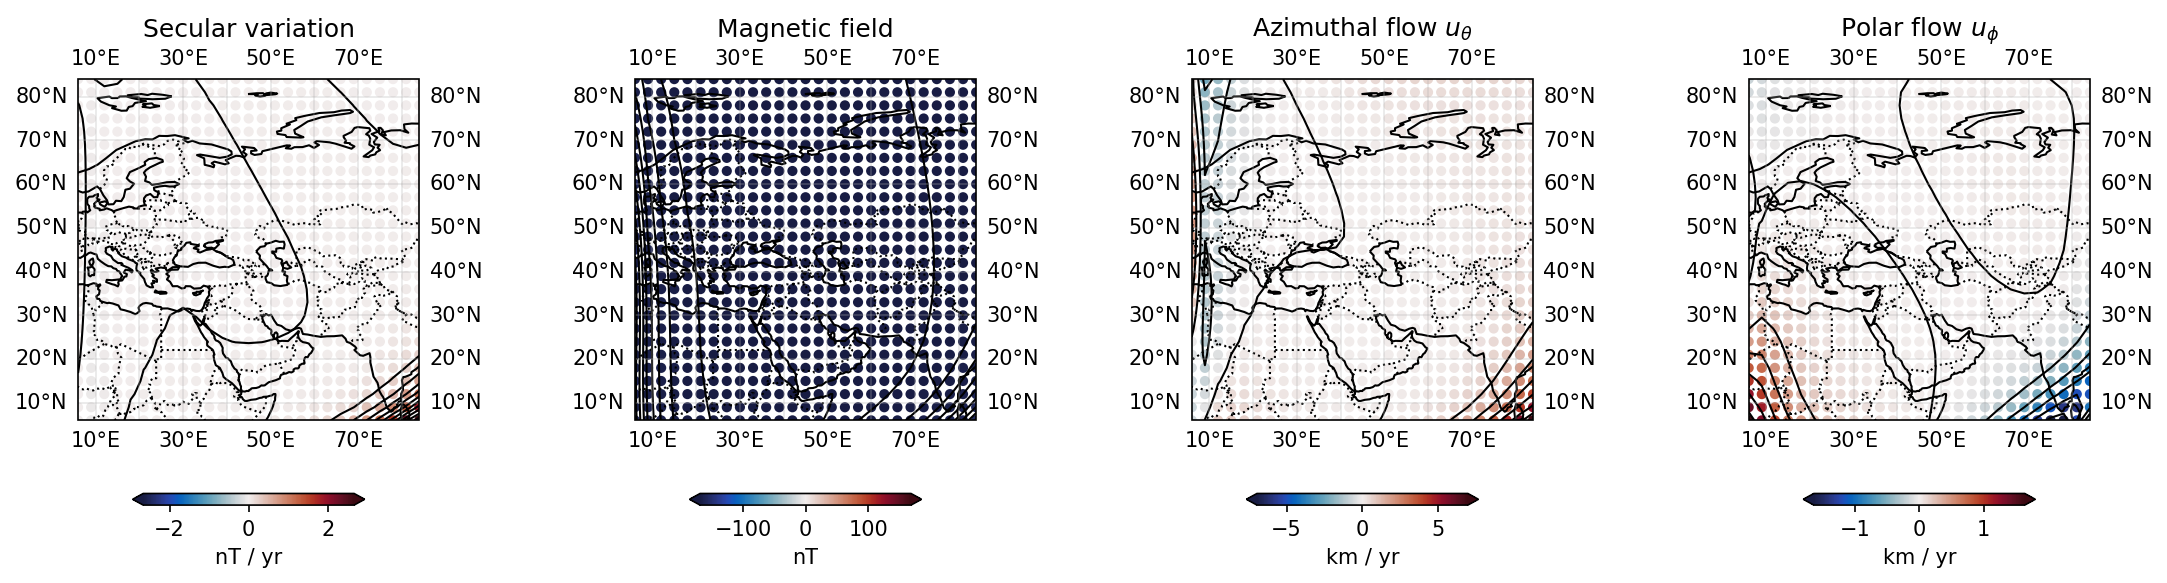

In [29]:
maps = ["dbrdt", "br", "uth", "uph"]

fig, axes = plt.subplots(1, len(maps), subplot_kw={'projection': ccrs.PlateCarree()}, sharex=True, sharey=True, figsize=(15, 4), dpi=150)

for n, map in enumerate(maps):
    pred = predictions[map]

    # Maximum value took by the observations
    vmax = numpy.max(numpy.abs(pred))

    # Arguments for the plot
    kwargs = {"cmap": cmocean.cm.balance, "vmin": -vmax, "vmax": vmax, "s": 15, "marker": "o"}

    cb = axes[n].scatter(long_grid, lat_grid, c=pred, **kwargs)

    axes[n].contour(long_grid, lat_grid, pred, colors=['black'], levels=10, linewidths=1, linestyles="solid")

    axes[n].coastlines(resolution='110m')
    axes[n].add_feature(cfeature.BORDERS, linestyle=':')
    axes[n].gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False, alpha=0.3)
    axes[n].set_title(suptitles[map])

    cbar = plt.colorbar(cb, orientation="horizontal", shrink=0.5, extend="both")

    cbar.set_label(units[map])

plt.tight_layout()

fig.savefig(os.path.join(fig_dir, f"prediction.png"))

### 9) Losses

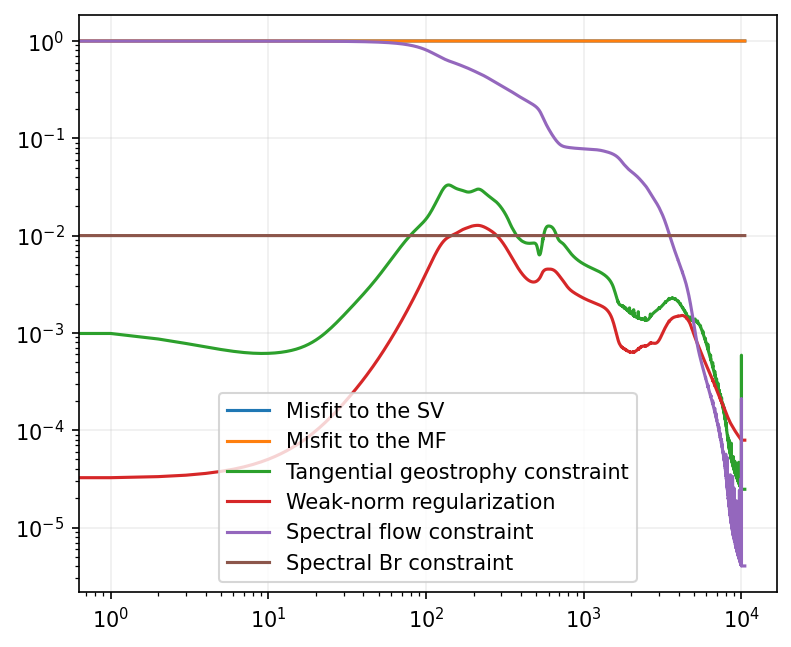

In [30]:
labels = {
    "misfit_dbrdt": "Misfit to the SV",
    "misfit_br": "Misfit to the MF",
    "tangential_geostrophy": "Tangential geostrophy constraint",
    "toroidal": "Toroidality constraint",
    "weak_norm": "Weak-norm regularization",
    "strong_norm": "Strong-norm regularization",
    "frozen_br": "Frozen-flux hypothesis on Br",
    "spectral_br": "Spectral Br constraint",    
    "spectral_u": "Spectral flow constraint"     
}


fig, ax = plt.subplots(1, 1, figsize=(6, 5), dpi=150)

for name in saved_losses:
    ax.loglog(saved_losses[name], label=labels[name])

ax.grid(alpha=0.2)
ax.legend()

fig.savefig(os.path.join(fig_dir, "losses.png"))

### 10) Diagnostics

In [31]:
name = "uth"

obs = observations[name][slice_thetas, slice_phis]
pred = predictions[name]
Δ = numpy.abs(obs - pred)

rmse = numpy.sqrt(numpy.mean(Δ**2))
re_max = 100 * Δ.mean() / numpy.abs(obs).max()

print(f"RMSE = {rmse:.2E} {units[name]}")
print(f"Relative error (% of max) = {re_max:.2E}")

print(f"{name}\t{rmse:.2E} {units[name]}\t{round(re_max, 2)} % of max.")

RMSE = 6.11E+00 km / yr
Relative error (% of max) = 3.39E+01
uth	6.11E+00 km / yr	33.94 % of max.


In [32]:

EPS = 1e-2
EPS_DEN = 1e-12

# Sliced obs/pred
uθ_obs = observations["uth"][slice_thetas, slice_phis]
uφ_obs = observations["uph"][slice_thetas, slice_phis]
uθ     = predictions["uth"]
uφ     = predictions["uph"]

# Grid + surface weights
θ = thetas[slice_thetas]
φ = phis[slice_phis]
sinθ = numpy.sin(thetas_grid[slice_thetas, slice_phis]).clip(EPS, 1)
cosθ = numpy.cos(thetas_grid[slice_thetas, slice_phis])
dθ = numpy.gradient(thetas).mean()
dφ = numpy.gradient(phis).mean()
dΩ = sinθ * dθ * dφ
area = numpy.sum(dΩ)

# 1) Energy-weighted correlation
Corr_obs_obs   = numpy.sum((uθ_obs**2 + uφ_obs**2) * dΩ)
Corr_pred_pred = numpy.sum((uθ**2 + uφ**2) * dΩ)
Corr_obs_pred  = numpy.sum((uθ_obs * uθ + uφ_obs * uφ) * dΩ)
Corr = Corr_obs_pred / numpy.sqrt((Corr_obs_obs + EPS_DEN) * (Corr_pred_pred + EPS_DEN))
print(f"Correlation: {Corr:.3f}")

# 2) Complexity metrics (weak/strong norms, TG, toroidality)
duθdθ = numpy.gradient(uθ, θ, axis=0)
duθdφ = numpy.gradient(uθ, φ, axis=1)
duφdθ = numpy.gradient(uφ, θ, axis=0)
duφdφ = numpy.gradient(uφ, φ, axis=1)

d2uθdθ = numpy.gradient(duθdθ, θ, axis=0)
d2uθdφ = numpy.gradient(duθdφ, φ, axis=1)
d2uφdθ = numpy.gradient(duφdθ, θ, axis=0)
d2uφdφ = numpy.gradient(duφdφ, φ, axis=1)

Δuθ = (1 / (r**2 * sinθ)) * (cosθ * duθdθ + sinθ * d2uθdθ) + (1 / (r * sinθ)**2) * d2uθdφ
Δuφ = (1 / (r**2 * sinθ)) * (cosθ * duφdθ + sinθ * d2uφdθ) + (1 / (r * sinθ)**2) * d2uφdφ

divh_uh = (1 / (r * sinθ)) * (duθdθ * sinθ + uθ * cosθ + duφdφ)

weak_norm   = numpy.sum((uθ**2 + uφ**2) * dΩ) / area
strong_norm = numpy.sum((Δuθ**2 + Δuφ**2) * dΩ) / area
tangential_geostrophy = (cosθ * divh_uh - uθ * sinθ / r).mean()
toroidality = divh_uh.mean()

print(f"Weak norm: {weak_norm:.2E}")
print(f"Strong norm: {strong_norm:.2E}")
print("---")
print(f"Tangential geostrophy: {tangential_geostrophy:.2E}")
print(f"Toroidality: {toroidality:.2E}")

# 3) SV misfit
dbrdt_obs  = observations["dbrdt"][slice_thetas, slice_phis]
dbrdt_pred = predictions["dbrdt"]
L1 = ((dbrdt_obs - dbrdt_pred)**2).mean() / (dbrdt_obs**2).mean()
print("---")
print(f"Misfit: {L1:.2E}")


Correlation: 0.012
Weak norm: 7.90E-01
Strong norm: 1.51E-08
---
Tangential geostrophy: 6.28E-06
Toroidality: 1.83E-04
---
Misfit: 1.00E+00
